# FCR day: simulated profile vs. Neware test results

Compares the simulated cell-level FCR day profile from `DEV_demo_FCR_day.ipynb`
(current, voltage, SOC of the OCV+R0 model) with what the tester actually
recorded when running `output/generated_cell_profile_FCR_day.txt`.

- Measured data: the FCR-day workbooks in `testresults/` (`TEST_RESULTS_GLOB`),
  sheet `record`, rows of the `SIM` step only. The preconditioning before it (discharge, recharge, rests)
  and the rest after it are not part of the comparison; the recharge is only
  read to know at which SOC the cell entered the SIM step.
- All currents are shown in the tester's convention: **positive = charge**.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

# Repo root (holds the toolchain modules and data), whether the kernel starts in
# comparison/ or in the root itself
MODULE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "profile_generation.py").exists())
if str(MODULE_DIR) not in sys.path:
    sys.path.insert(0, str(MODULE_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from select_representative_window import select_representative_window
from filter_profile import filter_profile
from cell_model_io import load_cell_model_xlsx, make_sim_cell_model
from profile_generation import run_battery_model
from _pg_helpers import apply_default_options, apply_default_datasheet

plt.rcParams["figure.dpi"] = 110

DATA_PATH = MODULE_DIR / "sample_data/FCR_1PE_LFP.csv"
CELL_MODEL_PATH = MODULE_DIR / "sample_data/LGM50LT_A.xlsx"
NEWARE_PROFILE_PATH = MODULE_DIR / "output/generated_cell_profile_FCR_day.txt"
TEST_RESULTS_DIR = MODULE_DIR / "testresults"
TEST_RESULTS_GLOB = "*-2818580845*.xlsx"  # FCR-day run only (ch 2-5 and 2-6)

# Already-tuned best values from DEV_demo_FCR_day.ipynb, so we just re-run the
# single best combination instead of the grid search.
SCALE_DIVISOR = 86000
DRIFT_CORRECTION = 0.83
ETA_COULOMB = 0.99

# SOC (%) at which the cells entered the SIM step. None -> taken from the test
# itself: Ah charged in the last charge step before SIM, counted from empty.
SOC_START_TEST = None

## 1. Simulated profile

Same selection / filter / model settings as `DEV_demo_FCR_day.ipynb`. The
regenerated current is checked against the exported Neware file, so the
simulation below is guaranteed to be the profile that ran on the tester.

In [2]:
df = pd.read_csv(DATA_PATH)
power = df["power_W"].to_numpy()
soc = df["soc_pct"].to_numpy()
dt = int(df["time_s"].iloc[1] - df["time_s"].iloc[0])

win = select_representative_window(
    power, dt=dt, window_sec=24 * 3600, soc=soc,
    metrics=["PosWh", "RT", "Nswap", "Eswap"],
)
filt = filter_profile(
    win.best_window_power, soc=win.best_window_soc,
    filter_rest_threshold=5.0, dt=dt, keep_rest_sec=300,
)

dsoc = np.diff(filt.soc_f)
p = filt.power_f[:-1]
charging_positive = p[dsoc > 0].mean() > 0

cm = load_cell_model_xlsx(CELL_MODEL_PATH)
sim_model = make_sim_cell_model(cm)
datasheet = apply_default_datasheet(cm.datasheet)

profile_data = {"power": filt.power_f, "soc": filt.soc_f}
opts = apply_default_options({
    "dt": dt,
    "scale_divisor": SCALE_DIVISOR,
    "drift_correction": DRIFT_CORRECTION,
    "use_current_limit": True,
    "eta_coulomb_ef": ETA_COULOMB,
    "charging_positive": charging_positive,
})

best = run_battery_model(profile_data, "power_soc", sim_model, datasheet, opts)
assert best.is_valid, best.message

# Tester convention: positive current is charge
sim_current = best.current if charging_positive else -best.current
n = sim_current.size

# The Neware file has one extra trailing 0 A row that the tester does not execute
neware = np.loadtxt(NEWARE_PROFILE_PATH)
assert neware.shape[0] == n + 1, "exported profile length differs from the simulation"
assert np.allclose(neware[:-1, 0], dt), "exported hold times differ from dt"
max_dev = np.max(np.abs(neware[:-1, 1] - sim_current))
assert max_dev < 1e-9, f"exported profile differs from the simulation (max {max_dev:.3g} A)"

print(f"Simulated profile: {n:,} rows @ dt={dt}s ({n * dt / 3600:.1f} h), "
      f"matches {NEWARE_PROFILE_PATH}")
print(f"simulated start SOC: {best.soc[0]:.1f} %, model capacity: {cm.capacity_Ah} Ah")

Simulated profile: 86,400 rows @ dt=1s (24.0 h), matches /Users/tomasdolezal/Documents/Baterky/Projects/TestProfiles/BatteryTestProfileGeneration/output/generated_cell_profile_FCR_day.txt
simulated start SOC: 58.9 %, model capacity: 4.589 Ah


## 2. Test results (`record` sheet, `SIM` step only)

The SIM step is logged every 10 s while the profile changes every second, so
each measured sample is compared with the simulated row that was being
executed at that instant: a sample at step time `t` falls at the end of
profile row `t/dt` (1-based).

In [3]:
def load_sim_step(path):
    """Returns the SIM-step rows of a Neware export (time / V / I / net Ah / T)
    and the Ah charged in the last charge step before it."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # openpyxl: "Workbook contains no default style"
        rec = pd.read_excel(path, sheet_name="record")
    sim = rec[rec["Step Type"] == "SIM"]
    if sim.empty:
        raise ValueError(f"{path}: no SIM step in sheet 'record'")
    if sim["Step ID"].nunique() != 1:
        raise ValueError(f"{path}: more than one SIM step, pick one explicitly")

    before = rec.loc[: sim.index[0] - 1]
    chg = before[before["Step Type"].str.contains("Chg") & ~before["Step Type"].str.contains("DChg")]
    precharge_Ah = np.nan
    if not chg.empty:
        precharge_Ah = chg.loc[chg["Step ID"] == chg["Step ID"].iloc[-1], "Capacity(Ah)(Ah)"].iloc[-1]

    meas = pd.DataFrame({
        "t_s": pd.to_timedelta(sim["Step Time"]).dt.total_seconds().to_numpy(),
        "voltage_V": sim["Voltage(V)(V)"].to_numpy(),
        "current_A": sim["Current(A)(A)"].to_numpy(),
        "capacity_Ah": sim["Capacity(Ah)(Ah)"].to_numpy(),
        "temp_degC": sim["T1(℃)"].to_numpy(),
    })
    return meas, precharge_Ah


measured = {}
soc_start_by_cell = {}

for path in sorted(TEST_RESULTS_DIR.glob(TEST_RESULTS_GLOB)):
    meas, precharge_Ah = load_sim_step(path)
    label = "ch " + "-".join(path.stem.split("-")[1:3])  # e.g. 240045-2-5-... -> ch 2-5
    measured[label] = meas
    soc_start_by_cell[label] = precharge_Ah / cm.capacity_Ah * 100
    print(f"{label}: {len(meas):,} SIM samples over {meas['t_s'].iloc[-1] / 3600:.1f} h, "
          f"recharged {precharge_Ah:.3f} Ah before SIM -> {soc_start_by_cell[label]:.1f} % SOC, "
          f"{meas['voltage_V'].iloc[0]:.3f} V at SIM start  ({path.name})")

if not measured:
    raise FileNotFoundError(f"no {TEST_RESULTS_GLOB} test results found in {TEST_RESULTS_DIR}/")

if SOC_START_TEST is None:
    soc_start_test = float(np.mean(list(soc_start_by_cell.values())))
    if not np.isfinite(soc_start_test):
        raise ValueError("no charge step before SIM -- set SOC_START_TEST by hand")
else:
    soc_start_test = float(SOC_START_TEST)

ocv_at = lambda s: np.interp(s, cm.soc * 100, cm.ocv)
print()
print(f"simulated start SOC: {best.soc[0]:.1f} %  (model OCV {ocv_at(best.soc[0]):.3f} V)")
print(f"tested start SOC:    {soc_start_test:.1f} %  (model OCV {ocv_at(soc_start_test):.3f} V)")

ch 2-5: 8,641 SIM samples over 24.0 h, recharged 2.295 Ah before SIM -> 50.0 % SOC, 3.769 V at SIM start  (240045-2-5-2818580845_fcr_day1.xlsx)


ch 2-6: 8,641 SIM samples over 24.0 h, recharged 2.295 Ah before SIM -> 50.0 % SOC, 3.768 V at SIM start  (240045-2-6-2818580845_fcr_day1.xlsx)

simulated start SOC: 58.9 %  (model OCV 3.848 V)
tested start SOC:    50.0 %  (model OCV 3.738 V)


### Start-SOC mismatch

The cells entered the SIM step at a different SOC than the simulation assumes,
which shifts the whole measured voltage trace. To separate that from the model
error itself, the same OCV+R0 model is also run with the same commanded current
from the **tested** start SOC. Both simulated variants are compared below:

- **as generated** -- the profile exactly as produced by `DEV_demo_FCR_day.ipynb`
- **from tested start SOC** -- same current and model, start SOC taken from the test

In [4]:
def simulate_from_current(current_chg_pos, soc0):
    """OCV+R0 model driven by current (positive = charge), same update rule as
    run_battery_model. Returns per-row voltage and SOC (n + 1 values, row edges)."""
    eff = np.where(current_chg_pos > 0, ETA_COULOMB, 1.0)
    dsoc = eff * current_chg_pos / (cm.capacity_Ah * 3600) * 100 * dt
    soc_edges = soc0 + np.concatenate([[0.0], np.cumsum(dsoc)])
    soc_row = soc_edges[:-1]  # SOC at the start of each row, as in run_battery_model
    voltage = np.interp(soc_row, cm.soc * 100, cm.ocv) \
        + current_chg_pos * np.interp(soc_row, cm.soc * 100, cm.r0)
    return voltage, soc_edges


# Sanity check: from the simulated start SOC this must reproduce run_battery_model
v_check, soc_check = simulate_from_current(sim_current, best.soc[0])
assert np.allclose(v_check[:-1], best.voltage[:-1], atol=1e-6), "voltage re-simulation mismatch"
assert np.allclose(soc_check[:-1], best.soc, atol=1e-6), "SOC re-simulation mismatch"

v_test, soc_test = simulate_from_current(sim_current, soc_start_test)

# name -> (voltage per row, SOC at row edges, plot color)
SIMS = {
    "as generated": (v_check, soc_check, "black"),
    "from tested start SOC": (v_test, soc_test, "tab:blue"),
}

results = {}
for label, meas in measured.items():
    # profile row (0-based) that ends at each measured sample; the sample at
    # t = 0 is taken before the first row starts, so it is dropped
    row = np.ceil(meas["t_s"].to_numpy() / dt).astype(int) - 1
    keep = (row >= 0) & (row < n)
    meas, row = meas[keep].reset_index(drop=True), row[keep]

    cmp = pd.DataFrame({
        "t_h": meas["t_s"] / 3600,
        "I_meas": meas["current_A"],
        "I_sim": sim_current[row],
        "V_meas": meas["voltage_V"],
        # measured SOC: tester's net Ah counter for the SIM step on top of the tested start SOC
        "soc_meas": soc_start_test + meas["capacity_Ah"] / cm.capacity_Ah * 100,
        "temp_degC": meas["temp_degC"],
    })
    for name, (v, soc_edges, _) in SIMS.items():
        cmp[f"V_sim [{name}]"] = v[row]
        cmp[f"soc_sim [{name}]"] = soc_edges[row + 1]  # SOC at the end of the row
    results[label] = cmp

## 3. Error metrics

In [5]:
def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


rows = []
for label, c in results.items():
    row = {
        "cell": label,
        "current RMSE / mA": 1000 * rmse(c["I_meas"], c["I_sim"]),
        "net charge, measured / Ah": c["soc_meas"].iloc[-1] / 100 * cm.capacity_Ah
                                     - soc_start_test / 100 * cm.capacity_Ah,
        "net charge, commanded / Ah": sim_current.sum() * dt / 3600,
        "T min / degC": c["temp_degC"].min(),
        "T max / degC": c["temp_degC"].max(),
    }
    for name in SIMS:
        dV = c["V_meas"] - c[f"V_sim [{name}]"]
        row[f"voltage RMSE / mV [{name}]"] = 1000 * rmse(c["V_meas"], c[f"V_sim [{name}]"])
        row[f"voltage mean error / mV [{name}]"] = 1000 * dV.mean()
        row[f"voltage max |error| / mV [{name}]"] = 1000 * dV.abs().max()
    name = "from tested start SOC"
    row[f"SOC RMSE / % [{name}]"] = rmse(c["soc_meas"], c[f"soc_sim [{name}]"])
    row[f"SOC end, measured / %"] = c["soc_meas"].iloc[-1]
    row[f"SOC end, simulated / % [{name}]"] = c[f"soc_sim [{name}]"].iloc[-1]
    rows.append(row)

metrics = pd.DataFrame(rows).set_index("cell")
metrics.T.round(3)

cell,ch 2-5,ch 2-6
current RMSE / mA,1.688,0.970
"net charge, measured / Ah",0.119,0.111
"net charge, commanded / Ah",0.114,0.114
T min / degC,24.600,24.700
T max / degC,25.700,25.700
voltage RMSE / mV [as generated],69.774,70.427
voltage mean error / mV [as generated],-67.829,-68.636
voltage max |error| / mV [as generated],107.354,107.176
voltage RMSE / mV [from tested start SOC],19.029,18.285
voltage mean error / mV [from tested start SOC],17.150,16.343


## 4. Plots

Error is always `measured - simulated`.

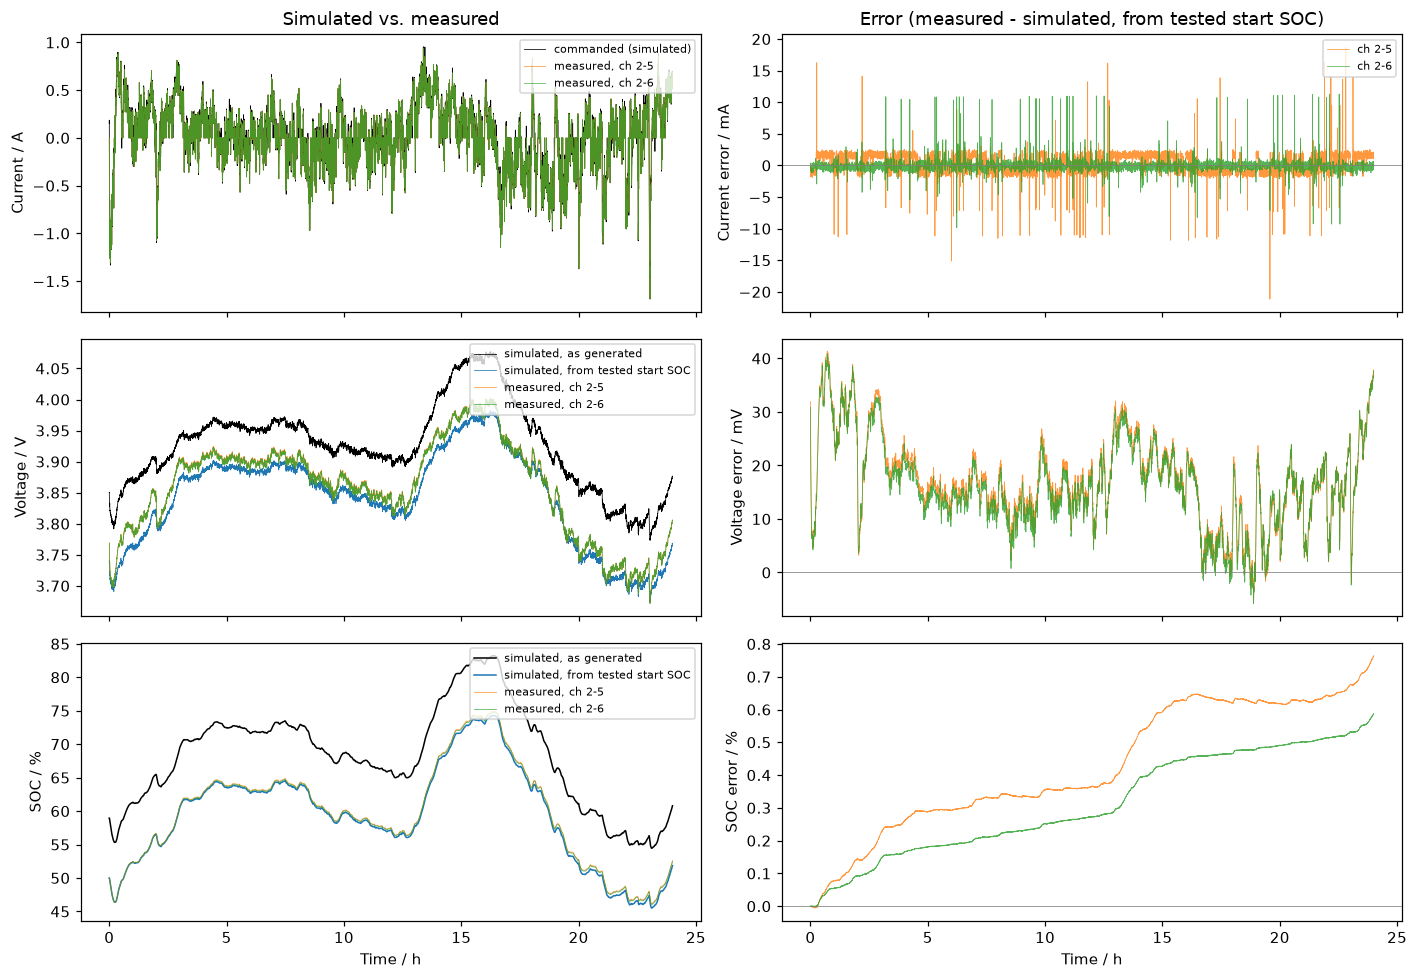

In [6]:
t_row_h = (np.arange(n) + 1) * dt / 3600   # end of each profile row
t_edge_h = np.arange(n + 1) * dt / 3600    # row edges (SOC)
colors = ["tab:orange", "tab:green", "tab:purple", "tab:brown"]
ERR_SIM = "from tested start SOC"

fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex=True)

# current
axes[0, 0].plot(t_row_h, sim_current, color="black", lw=0.5, label="commanded (simulated)")
for (label, c), color in zip(results.items(), colors):
    axes[0, 0].plot(c["t_h"], c["I_meas"], color=color, lw=0.5, alpha=0.8, label=f"measured, {label}")
    axes[0, 1].plot(c["t_h"], 1000 * (c["I_meas"] - c["I_sim"]), color=color, lw=0.5, alpha=0.8, label=label)
axes[0, 0].set_ylabel("Current / A")
axes[0, 1].set_ylabel("Current error / mA")

# voltage and SOC
for i, (key, ylabel, err_label, err_scale) in enumerate([
        ("V", "Voltage / V", "Voltage error / mV", 1000),
        ("soc", "SOC / %", "SOC error / %", 1)], start=1):
    for name, (v, soc_edges, sim_color) in SIMS.items():
        if key == "V":
            axes[i, 0].plot(t_row_h, v, color=sim_color, lw=0.5, label=f"simulated, {name}")
        else:
            axes[i, 0].plot(t_edge_h, soc_edges, color=sim_color, lw=1.0, label=f"simulated, {name}")
    for (label, c), color in zip(results.items(), colors):
        axes[i, 0].plot(c["t_h"], c[f"{key}_meas"], color=color, lw=0.5, alpha=0.8,
                        label=f"measured, {label}")
        axes[i, 1].plot(c["t_h"], err_scale * (c[f"{key}_meas"] - c[f"{key}_sim [{ERR_SIM}]"]),
                        color=color, lw=0.5, alpha=0.8, label=label)
    axes[i, 0].set_ylabel(ylabel)
    axes[i, 1].set_ylabel(err_label)

for ax in axes[:, 1]:
    ax.axhline(0, color="0.5", lw=0.5)
for ax in axes[:, 0]:
    ax.legend(loc="upper right", fontsize=7)
axes[0, 1].legend(loc="upper right", fontsize=7)
axes[0, 0].set_title("Simulated vs. measured")
axes[0, 1].set_title(f"Error (measured - simulated, {ERR_SIM})")
axes[-1, 0].set_xlabel("Time / h")
axes[-1, 1].set_xlabel("Time / h")
plt.tight_layout()
plt.show()

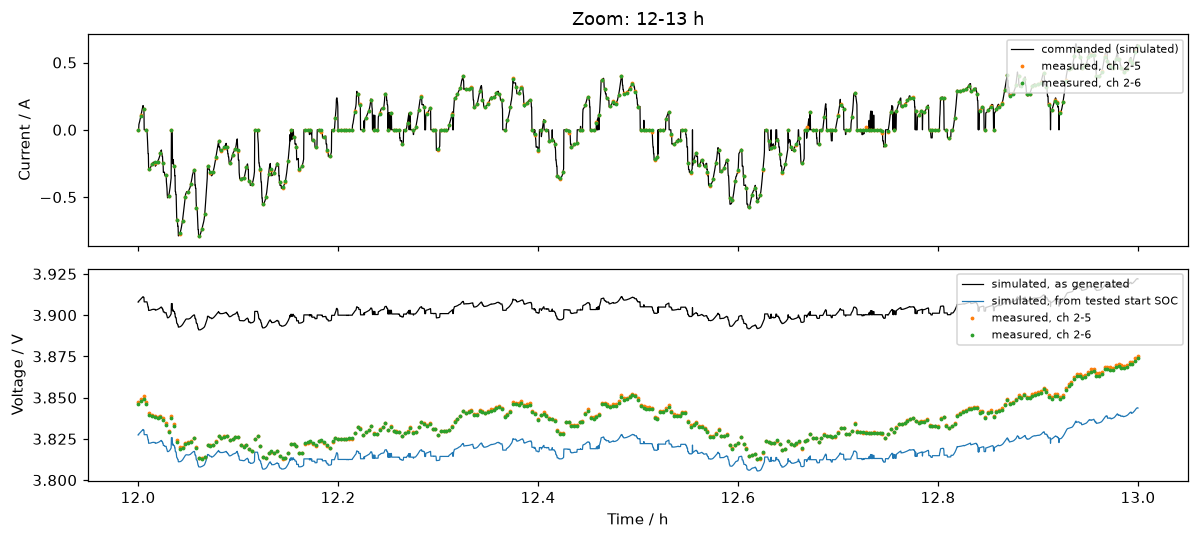

In [7]:
# Zoom on one hour, to see how well the 1 s dynamics are followed
ZOOM_START_H, ZOOM_LEN_H = 12.0, 1.0

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
zs = (t_row_h >= ZOOM_START_H) & (t_row_h <= ZOOM_START_H + ZOOM_LEN_H)
axes[0].plot(t_row_h[zs], sim_current[zs], color="black", lw=0.8, label="commanded (simulated)")
for name, (v, _, sim_color) in SIMS.items():
    axes[1].plot(t_row_h[zs], v[zs], color=sim_color, lw=0.8, label=f"simulated, {name}")
for (label, c), color in zip(results.items(), colors):
    zm = c["t_h"].between(ZOOM_START_H, ZOOM_START_H + ZOOM_LEN_H)
    axes[0].plot(c["t_h"][zm], c["I_meas"][zm], ".", ms=3, color=color, label=f"measured, {label}")
    axes[1].plot(c["t_h"][zm], c["V_meas"][zm], ".", ms=3, color=color, label=f"measured, {label}")
axes[0].set_ylabel("Current / A")
axes[1].set_ylabel("Voltage / V")
axes[1].set_xlabel("Time / h")
axes[0].set_title(f"Zoom: {ZOOM_START_H:g}-{ZOOM_START_H + ZOOM_LEN_H:g} h")
axes[0].legend(loc="upper right", fontsize=7)
axes[1].legend(loc="upper right", fontsize=7)
plt.tight_layout()
plt.show()

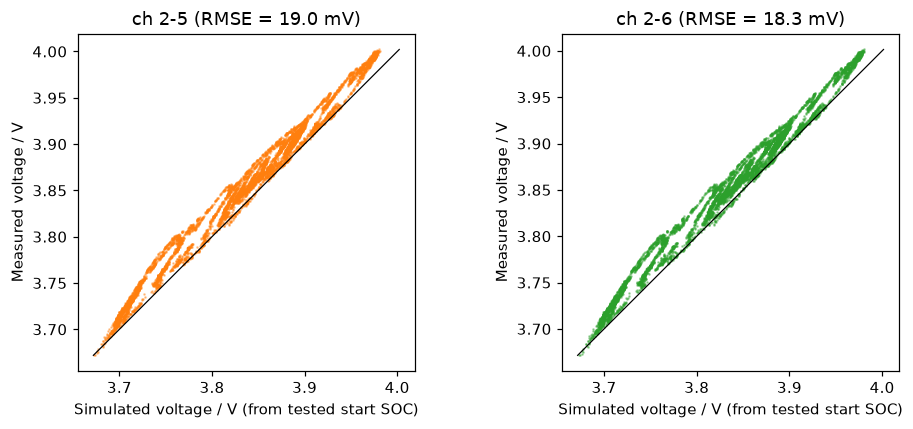

In [8]:
# Voltage parity: points on the diagonal mean the OCV+R0 model reproduces the cell
fig, axes = plt.subplots(1, len(results), figsize=(4.5 * len(results), 4), squeeze=False)
for ax, (label, c), color in zip(axes[0], results.items(), colors):
    v_sim = c[f"V_sim [{ERR_SIM}]"]
    ax.plot(v_sim, c["V_meas"], ".", ms=1.5, color=color, alpha=0.4)
    lims = [min(v_sim.min(), c["V_meas"].min()), max(v_sim.max(), c["V_meas"].max())]
    ax.plot(lims, lims, color="black", lw=0.8)
    ax.set_xlabel(f"Simulated voltage / V ({ERR_SIM})")
    ax.set_ylabel("Measured voltage / V")
    ax.set_title(f"{label} (RMSE = {1000 * rmse(c['V_meas'], v_sim):.1f} mV)")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()